In [1]:
import numpy as np
import os
import torch
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from tqdm.auto import tqdm
from pathlib import Path
import random
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

seed = 123456789
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)

PROJECT_PATH = Path(os.getcwd())
DATA_PATH = PROJECT_PATH.parent / "data/MNIST/raw"

BATCH_SIZE = 64
EPOCHS = 20
LR = 0.1

In [2]:
def load(path, offset):
    with open(path, "rb") as f:
        return np.fromfile(f, dtype=np.uint8, offset=offset)

def print_data_stats(x_tr, y_tr, x_v, y_v, x_t, y_t):
    print(f"{x_tr.shape=}, {x_tr.dtype}")
    print(f"{y_tr.shape=}, {y_tr.dtype}")
    print('-' * 15)
    print(f"{x_v.shape=}, {x_v.dtype}")
    print(f"{y_v.shape=}, {y_v.dtype}")
    print('-' * 15)
    print(f"{x_t.shape=}, {x_t.dtype}")
    print(f"{y_t.shape=}, {y_t.dtype}")

In [ ]:
# могу себе позволить сконвертировать в fp32 и long, чтобы torch и np работали с той же точностью инпута
x_train_raw = load(DATA_PATH / "train-images-idx3-ubyte", 16).reshape(-1, 784).astype(np.float32)
y_train_raw = load(DATA_PATH / "train-labels-idx1-ubyte", 8).astype(np.int64)
x_test_raw = load(DATA_PATH / "t10k-images-idx3-ubyte", 16).reshape(-1, 784).astype(np.float32)
y_test_raw = load(DATA_PATH / "t10k-labels-idx1-ubyte", 8).astype(np.int64)

# валидационный сет 10% от трена
x_train_raw, x_val_raw, y_train_raw, y_val_raw = train_test_split(
    x_train_raw,
    y_train_raw,
    test_size=0.1,
    random_state=seed,
    stratify=y_train_raw,
    shuffle=True,
)

print_data_stats(x_train_raw, y_train_raw, x_val_raw, y_val_raw, x_test_raw, y_test_raw)

x_tr.shape=(54000, 784), float32
y_tr.shape=(54000,), int64
---------------
x_v.shape=(6000, 784), float32
y_v.shape=(6000,), int64
---------------
x_t.shape=(10000, 784), float32
y_t.shape=(10000,), int64


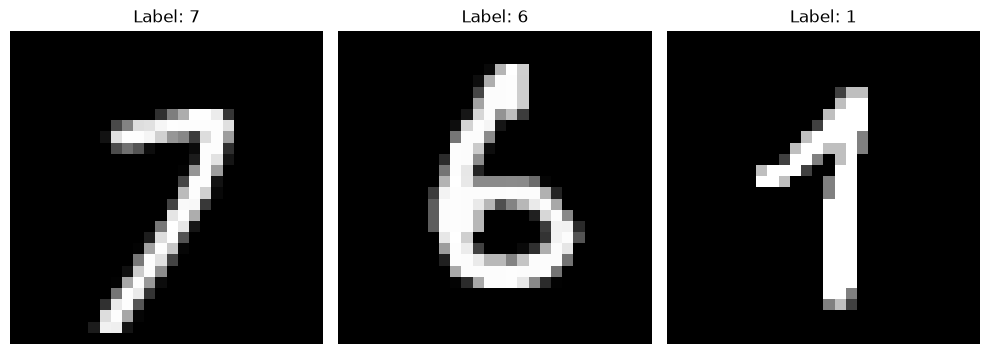

In [4]:
to_display = 3

sample_indices = np.random.choice(len(x_train_raw), size=to_display, replace=False)
fig, axes = plt.subplots(1, to_display, figsize=(10, 4))

for idx, ax in zip(sample_indices, axes):
    # решейпим (784, ) в (28, 28) для вывода изображения
    img = x_train_raw[idx].reshape(28, 28)
    label = y_train_raw[idx]

    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# one-hot для MSE-loss
y_train = np.eye(10, dtype=np.float32)[y_train_raw]
y_val = np.eye(10, dtype=np.float32)[y_val_raw]
y_test = np.eye(10, dtype=np.float32)[y_test_raw]

print(f"{y_train.shape=}, {y_train.dtype}")
print(f"{y_val.shape=}, {y_val.dtype}")
print(f"{y_test.shape=}, {y_test.dtype}")

y_train.shape=(54000, 10), float32
y_val.shape=(6000, 10), float32
y_test.shape=(10000, 10), float32


In [6]:
x_train_float = x_train_raw / 255.0
mean = x_train_float.mean()
std = x_train_float.std()

# z-score нормализация
x_train = (x_train_raw / 255.0 - mean) / std
x_val = (x_val_raw / 255.0 - mean) / std
x_test = (x_test_raw / 255.0 - mean) / std

print(f"Mean: {mean:.4f}")
print(f"Std: {std:.4f}")

print("-" * 40)
print(f"{x_train.mean()=},\n{x_train.std()=}")
print("-" * 40)
print(f"{x_val.mean()=},\n{x_val.std()=}")
print("-" * 40)
print(f"{x_test.mean()=},\n{x_test.std()=}")

Mean: 0.1307
Std: 0.3082
----------------------------------------
x_train.mean()=np.float32(5.139317e-08),
x_train.std()=np.float32(1.0000001)
----------------------------------------
x_val.mean()=np.float32(-0.0017959408),
x_val.std()=np.float32(0.9980425)
----------------------------------------
x_test.mean()=np.float32(0.0058370824),
x_test.std()=np.float32(1.0075032)


## Numpy train

In [7]:
import sys 
sys.path.append(PROJECT_PATH)
from src.model import LinearNP, ReLUNP, ModuleNP
from src.optim import SGDOptimizerNP
from src.criterion import mse_loss
from src.loader import DataLoaderNP
from src.train import train_one_epoch_np, evaluate_np


class MLPClassifierNP(ModuleNP):
    def __init__(self, in_features: int = 784, hidden: int = 128, num_classes: int = 10):
        super().__init__()
        self.fc1 = LinearNP(in_features, hidden)
        self.fc2 = LinearNP(hidden, num_classes)
        self.relu = ReLUNP()
    
    def forward(self, x: np.ndarray):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x
    
    def backward(self, dY: np.ndarray):
        dY = self.fc2.backward(dY)
        dY = self.relu.backward(dY)
        dY = self.fc1.backward(dY)
        return dY
    
    def parameters(self):
        return [self.fc1, self.fc2]

In [8]:
train_loader_np = DataLoaderNP(x_train, y_train, batch_size=BATCH_SIZE, shuffle=True, seed=seed)
val_loader_np = DataLoaderNP(x_val, y_val, batch_size=BATCH_SIZE, shuffle=False, seed=seed)
test_loader_np = DataLoaderNP(x_test, y_test,  batch_size=BATCH_SIZE, shuffle=False, seed=seed)

model_np = MLPClassifierNP(in_features=784, hidden=128, num_classes=10)
criterion_np = mse_loss
optimizer_np = SGDOptimizerNP(params=model_np.parameters(), lr=LR)

In [9]:
history_np = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_state = None

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch_np(model_np, train_loader_np, criterion_np, optimizer_np)
    val_loss, val_acc = evaluate_np(model_np, val_loader_np, criterion_np)

    history_np["train_loss"].append(tr_loss)
    history_np["train_acc"].append(tr_acc)
    history_np["val_loss"].append(val_loss)
    history_np["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        # аналог state_dict: копии W и b у каждого LinearNP
        best_state = {
            "fc1": {"W": model_np.fc1.W.copy(), "b": model_np.fc1.b.copy()},
            "fc2": {"W": model_np.fc2.W.copy(), "b": model_np.fc2.b.copy()},
        }

    print(f"epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

print(f"\nbest val acc: {best_val_acc:.4f}")

# восстановление лучшего состояния, костыльный load_state_dict из торча
model_np.fc1.W[...] = best_state["fc1"]["W"]
model_np.fc1.b[...] = best_state["fc1"]["b"]
model_np.fc2.W[...] = best_state["fc2"]["W"]
model_np.fc2.b[...] = best_state["fc2"]["b"]

test_loss, test_acc = evaluate_np(model_np, test_loader_np, criterion_np)
print(f"test loss {test_loss:.4f} acc {test_acc:.4f}")

train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 01/20 | train loss 0.0306 acc 0.8823 | val loss 0.0215 acc 0.9273


train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 02/20 | train loss 0.0191 acc 0.9351 | val loss 0.0178 acc 0.9367


train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 03/20 | train loss 0.0163 acc 0.9463 | val loss 0.0158 acc 0.9452


... (30 outputs left out)

train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 19/20 | train loss 0.0088 acc 0.9763 | val loss 0.0100 acc 0.9663


train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 20/20 | train loss 0.0086 acc 0.9771 | val loss 0.0100 acc 0.9677

best val acc: 0.9677
test loss 0.0097 acc 0.9699


## Torch train

In [10]:
def to_tensor(x, y):
    return torch.from_numpy(x), torch.from_numpy(y)

x_train_torch, y_train_torch = to_tensor(x_train, y_train)
x_val_torch, y_val_torch = to_tensor(x_val, y_val)
x_test_torch, y_test_torch = to_tensor(x_test, y_test)

print_data_stats(x_train_torch, y_train_torch, x_val_torch, y_val_torch, x_test_torch, y_test_torch)

x_tr.shape=torch.Size([54000, 784]), torch.float32
y_tr.shape=torch.Size([54000, 10]), torch.float32
---------------
x_v.shape=torch.Size([6000, 784]), torch.float32
y_v.shape=torch.Size([6000, 10]), torch.float32
---------------
x_t.shape=torch.Size([10000, 784]), torch.float32
y_t.shape=torch.Size([10000, 10]), torch.float32


In [11]:
class MLPClassifier(torch.nn.Module):
    def __init__(self, in_features: int = 784, hidden: int = 128, num_classes: int = 10):
        super().__init__()
        self.fc1 = torch.nn.Linear(in_features, hidden)
        self.fc2 = torch.nn.Linear(hidden, num_classes)
        self.relu = torch.nn.ReLU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x


# Сид торча был выставлен в начале + энв переменная. Даталоадеры должны схавать мой сид
train_loader_torch = DataLoader(
    TensorDataset(x_train_torch, y_train_torch), 
    batch_size=BATCH_SIZE, 
    shuffle=True,
)

val_loader_torch = DataLoader(
    TensorDataset(x_val_torch, y_val_torch), 
    batch_size=BATCH_SIZE, 
    shuffle=False,
)

test_loader_torch = DataLoader(
    TensorDataset(x_test_torch, y_test_torch), 
    batch_size=BATCH_SIZE, 
    shuffle=False,
)

model_torch = MLPClassifier(in_features=784, hidden=128, num_classes=10)
criterion_torch = torch.nn.MSELoss()
optimizer_torch = torch.optim.SGD(model_torch.parameters(), lr=LR)

In [12]:
def train_one_epoch_torch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total = 0
    pbar = tqdm(loader, desc="train", leave=False)
    for xb, yb in pbar:
        optimizer.zero_grad()
        logits = model(xb) # forward на батч
        loss = criterion(logits, yb) # MSE на батч
        loss.backward()
        optimizer.step()

        bs = xb.size(0)
        total_loss += loss.item() * bs
        # суммируем где сошлись аутпуты модели с oh меткой
        total_correct += (logits.argmax(dim=1) == yb.argmax(dim=1)).sum().item()
        total += bs
        pbar.set_postfix(loss=f"{total_loss/total:.4f}", acc=f"{total_correct/total:.4f}")
    return total_loss / total, total_correct / total

@torch.inference_mode()
def evaluate_torch(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total = 0
    for xb, yb in loader:
        logits = model(xb)
        loss = criterion(logits, yb)

        bs = xb.size(0)
        total_loss += loss.item() * bs
        # суммируем где сошлись аутпуты модели с oh меткой
        total_correct += (logits.argmax(dim=1) == yb.argmax(dim=1)).sum().item()
        total += bs
    return total_loss / total, total_correct / total

In [13]:
history_torch = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_state = None

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch_torch(model_torch, train_loader_torch, criterion_torch, optimizer_torch)
    val_loss, val_acc = evaluate_torch(model_torch, val_loader_torch, criterion_torch)

    history_torch["train_loss"].append(tr_loss)
    history_torch["train_acc"].append(tr_acc)
    history_torch["val_loss"].append(val_loss)
    history_torch["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.clone() for k, v in model_torch.state_dict().items()}

    print(f"epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

print(f"\nbest val acc: {best_val_acc:.4f}")

model_torch.load_state_dict(best_state)
test_loss, test_acc = evaluate_torch(model_torch, test_loader_torch, criterion_torch)
print(f"test loss {test_loss:.4f} acc {test_acc:.4f}")

train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 01/20 | train loss 0.0307 acc 0.8827 | val loss 0.0217 acc 0.9257


train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 02/20 | train loss 0.0189 acc 0.9379 | val loss 0.0178 acc 0.9395


train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 03/20 | train loss 0.0161 acc 0.9474 | val loss 0.0160 acc 0.9445


... (30 outputs left out)

train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 19/20 | train loss 0.0088 acc 0.9766 | val loss 0.0102 acc 0.9638


train:   0%|          | 0/844 [00:00<?, ?it/s]

epoch 20/20 | train loss 0.0086 acc 0.9774 | val loss 0.0100 acc 0.9657

best val acc: 0.9657
test loss 0.0095 acc 0.9707


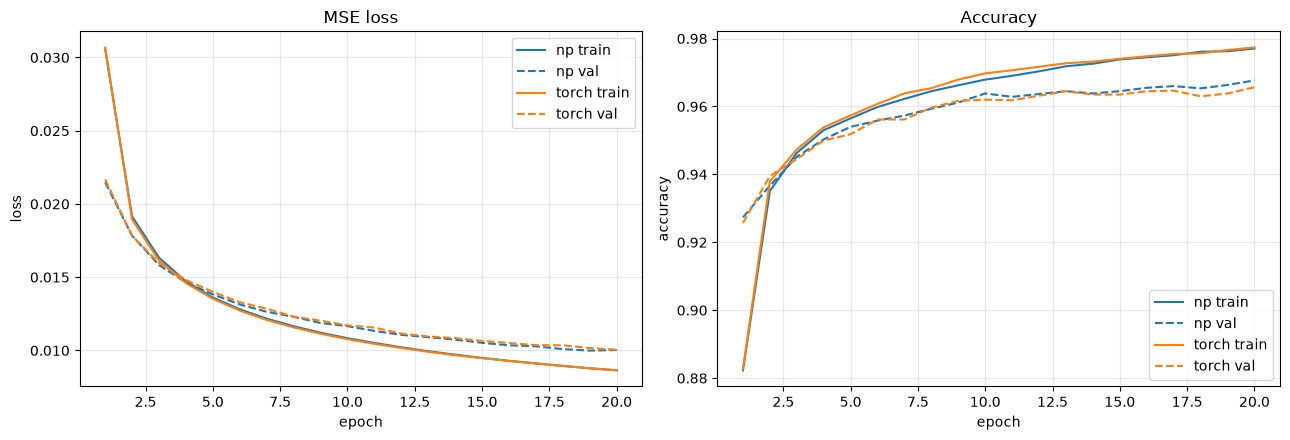

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def plot_history_compare(history_np, history_torch, title_suffix=""):
    epochs = np.arange(1, len(history_np["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    ax = axes[0]
    ax.plot(epochs, history_np["train_loss"], color="tab:blue", linestyle="-", label="np train")
    ax.plot(epochs, history_np["val_loss"], color="tab:blue",  linestyle="--", label="np val")
    ax.plot(epochs, history_torch["train_loss"], color="tab:orange", linestyle="-", label="torch train")
    ax.plot(epochs, history_torch["val_loss"], color="tab:orange", linestyle="--", label="torch val")
    ax.set_title(f"MSE loss{title_suffix}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

    ax = axes[1]
    ax.plot(epochs, history_np["train_acc"], color="tab:blue", linestyle="-", label="np train")
    ax.plot(epochs, history_np["val_acc"], color="tab:blue", linestyle="--", label="np val")
    ax.plot(epochs, history_torch["train_acc"], color="tab:orange", linestyle="-",  label="torch train")
    ax.plot(epochs, history_torch["val_acc"], color="tab:orange", linestyle="--", label="torch val")
    ax.set_title(f"Accuracy{title_suffix}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("accuracy")
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


plot_history_compare(history_np, history_torch)

## Важное замечание

Тренировки не совпадают полностью, потому что всё ещё веса инициализируются чуть иначе, хоть я и стремился повторить эталонный инит весов из торча. Также повлияли то, что внутри numpy и torch разные методы генерации случайных чисел.

То есть есть небольшой сдвиг в числах из-за изначальных весов, fp32 расчёта в двух разных движках, а также разная подача сэмплов в батчах.

В самом низу ноутбука будет сравнение моей реализации по исходным данным торча (веса модели и одинаковые батчи).

## Проверка реализаций
это писал жептер, не стал убирать, хорошие проверки

### type check 

In [15]:
import numpy as np
import torch

# один и тот же батч для обеих моделей
xb, yb = next(iter(train_loader_np))          # numpy, float32
assert xb.dtype == np.float32 and yb.dtype == np.float32

xb_t = torch.from_numpy(xb)                # без requires_grad, для forward
yb_t = torch.from_numpy(yb)

# dtype-санити
print("torch dtype:", model_torch.fc1.weight.dtype)
print("numpy dtype:", model_np.fc1.W.dtype)

# копируем веса torch → numpy: torch W (out, in) → numpy W (in, out)
def copy_lin(src, dst):
    dst.W = src.weight.detach().cpu().numpy().T.copy().astype(np.float32)
    dst.b = src.bias.detach().cpu().numpy().copy().astype(np.float32)

copy_lin(model_torch.fc1, model_np.fc1)
copy_lin(model_torch.fc2, model_np.fc2)
print("weights copied")

torch dtype: torch.float32
numpy dtype: float32
weights copied


### forward и logits

In [16]:
logits_np = model_np(xb)                                     # numpy forward

with torch.no_grad():
    logits_t = model_torch(xb_t)
logits_t_np = logits_t.numpy()

diff = np.abs(logits_np - logits_t_np)
print(f"logits:  max|diff| = {diff.max():.3e}   mean|diff| = {diff.mean():.3e}")
print(f"         logits_np[0,:4]  = {logits_np[0,:4]}")
print(f"         logits_torch[0,:4] = {logits_t_np[0,:4]}")

logits:  max|diff| = 5.960e-07   mean|diff| = 4.717e-08
         logits_np[0,:4]  = [0.168813   0.0334754  0.02341819 0.03983458]
         logits_torch[0,:4] = [0.168813   0.0334754  0.02341817 0.03983461]


### loss и dL/dlogits

In [17]:
# numpy
loss_np, dY_np = criterion_np(logits_np, yb)

# torch: лосс + dL/dlogits через autograd.grad (detach, чтобы не потекло в веса)
logits_t_req = logits_t.detach().requires_grad_(True)
loss_t = criterion_torch(logits_t_req, yb_t)
dY_t = torch.autograd.grad(loss_t, logits_t_req)[0].detach().numpy()

print(f"loss:    np = {loss_np:.8f}   torch = {loss_t.item():.8f}   "
      f"diff = {abs(loss_np - loss_t.item()):.3e}")
print(f"dY:      max|diff| = {np.abs(dY_np - dY_t).max():.3e}")

loss:    np = 0.00607366   torch = 0.00607366   diff = 7.451e-10
dY:      max|diff| = 1.839e-09


### backward (dW, db)

In [18]:
# torch
model_torch.zero_grad()
logits_t_full = model_torch(xb_t)              # с графом
loss_t_full = criterion_torch(logits_t_full, yb_t)
loss_t_full.backward()

# numpy — уже посчитан dY_np; model_np.backward(dY) заполнит .dW/.db и вернёт dX
dX_np = model_np.backward(dY_np)

def _diff(a_np, b_t):
    return float(np.abs(a_np - b_t.detach().cpu().numpy()).max())

print(f"fc1.W:  max|diff| = {_diff(model_np.fc1.dW, model_torch.fc1.weight.grad.T):.3e}")
print(f"fc1.b:  max|diff| = {_diff(model_np.fc1.db, model_torch.fc1.bias.grad):.3e}")
print(f"fc2.W:  max|diff| = {_diff(model_np.fc2.dW, model_torch.fc2.weight.grad.T):.3e}")
print(f"fc2.b:  max|diff| = {_diff(model_np.fc2.db, model_torch.fc2.bias.grad):.3e}")

fc1.W:  max|diff| = 3.096e-09
fc1.b:  max|diff| = 1.219e-09
fc2.W:  max|diff| = 4.862e-09
fc2.b:  max|diff| = 4.622e-09


In [19]:
# torch: dL/dX через autograd.grad по входу (не трогает .grad у весов)
xb_t_req = torch.from_numpy(xb.copy()).requires_grad_(True)
logits_t5 = model_torch(xb_t_req)
loss_t5 = criterion_torch(logits_t5, yb_t)
dX_t = torch.autograd.grad(loss_t5, xb_t_req)[0].detach().cpu().numpy()

print(f"dX:       max|diff| = {np.abs(dX_np - dX_t).max():.3e}")

dX:       max|diff| = 1.102e-10


In [20]:
import numpy as np

def ok(name, a, b, tol=1e-4):
    if isinstance(a, torch.Tensor):
        a = a.detach().cpu().numpy()
    if isinstance(b, torch.Tensor):
        b = b.detach().cpu().numpy()
    d = float(np.abs(a - b).max())
    mark = "OK  " if d < tol else "FAIL"
    print(f"  {mark} {name:10s}  max|diff| = {d:.3e}")

print("=== sanity: numpy vs torch ===")
ok("logits",  logits_np,        logits_t_np)
ok("dY",      dY_np,            dY_t)
ok("fc1.dW",  model_np.fc1.dW,  model_torch.fc1.weight.grad.T)
ok("fc1.db",  model_np.fc1.db,  model_torch.fc1.bias.grad)
ok("fc2.dW",  model_np.fc2.dW,  model_torch.fc2.weight.grad.T)
ok("fc2.db",  model_np.fc2.db,  model_torch.fc2.bias.grad)
ok("dX",      dX_np,            dX_t)
print(f"  loss: np={loss_np:.8f}  torch={loss_t_full.item():.8f}  "
      f"diff={abs(loss_np - loss_t_full.item()):.3e}")

=== sanity: numpy vs torch ===
  OK   logits      max|diff| = 5.960e-07
  OK   dY          max|diff| = 1.839e-09
  OK   fc1.dW      max|diff| = 3.096e-09
  OK   fc1.db      max|diff| = 1.219e-09
  OK   fc2.dW      max|diff| = 4.862e-09
  OK   fc2.db      max|diff| = 4.622e-09
  OK   dX          max|diff| = 1.102e-10
  loss: np=0.00607366  torch=0.00607366  diff=7.451e-10


## Сравнение реализаций из одних и тех же исходных данных
(это уже я писал)

In [ ]:
torch.manual_seed(2281337) # фиксируем сид

# Создаём 2 модели
# торч инитит "по-своему" веса, а я их копирую в NP-модель
model_twin_torch = MLPClassifier(784, 128, 10)
model_twin_np = MLPClassifierNP(784, 128, 10)
copy_lin(model_twin_torch.fc1, model_twin_np.fc1)
copy_lin(model_twin_torch.fc2, model_twin_np.fc2)

# получаем одни и теже данные
xb = x_train[:BATCH_SIZE].copy()
yb = y_train[:BATCH_SIZE].copy()
xb_t = torch.from_numpy(xb)
yb_t = torch.from_numpy(yb)

# создаём одни и те же SGD
opt_np = SGDOptimizerNP([model_twin_np.fc1, model_twin_np.fc2], LR)
opt_t = torch.optim.SGD(model_twin_torch.parameters(), lr=LR)

# mse-np уже давно был импортирован выше
criterion_t = torch.nn.MSELoss()


# макс разница между двумя по модулю
def max_abs_diff(a, b):
    return float(np.max(np.abs(a - b)))


# получаем логиты в начале у обеих моделей
with torch.inference_mode():
    logits_n = model_twin_np(xb)
    logits_t = model_twin_torch(xb_t)

# считаем какая разница
# >>> initial logits: max|diff| = 2.421e-07 - логиты очень похожи 
# (разница уже на уровне обработки fp32 только вычислений на разных движках)
print(f"initial logits: max|diff| = {max_abs_diff(logits_n, logits_t.numpy()):.3e}")
print(f"{'step':>4}  {'loss_np':>12}  {'loss_torch':>12}  "
      f"{'|dlogits|':>10}  {'|dY|':>10}  {'|dgrad|':>10}  {'|dparam|':>10}")

max_grad = 0.0
max_param = 0.0
max_dy = 0.0
max_logits = 0.0

for step in range(5): # делаем 5 эпох чисто для проверки
    
    # трен степ по нампаю
    logits_n = model_twin_np(xb)
    loss_n, dY_n = mse_loss(logits_n, yb)
    opt_np.zero_grad()
    model_twin_np.backward(dY_n)

    # трен степ по торчу
    logits_t = model_twin_torch(xb_t)
    loss_t = criterion_t(logits_t, yb_t)
    opt_t.zero_grad()
    logits_t.retain_grad() # сохраняем грады в атрибут тензоров, чтобы потом их получить
    loss_t.backward()
    dY_t = logits_t.grad.detach().numpy()

    # считаем разницу по dy и логитам
    logits_diff = max_abs_diff(logits_n, logits_t.detach().numpy())
    dy_diff = max_abs_diff(dY_n, dY_t)
    
    # считаем макс разницу в градах на любом из слоёв
    grad_diff = max(
        max_abs_diff(model_twin_np.fc1.dW, model_twin_torch.fc1.weight.grad.numpy().T),
        max_abs_diff(model_twin_np.fc1.db, model_twin_torch.fc1.bias.grad.numpy()),
        max_abs_diff(model_twin_np.fc2.dW, model_twin_torch.fc2.weight.grad.numpy().T),
        max_abs_diff(model_twin_np.fc2.db, model_twin_torch.fc2.bias.grad.numpy()),
    )

    # делаем степы оптимайзеров
    opt_np.step()
    opt_t.step()

    # считаем макс разницу между парамами моделек на любом из слоёв
    param_diff = max(
        max_abs_diff(model_twin_np.fc1.W, model_twin_torch.fc1.weight.detach().numpy().T),
        max_abs_diff(model_twin_np.fc1.b, model_twin_torch.fc1.bias.detach().numpy()),
        max_abs_diff(model_twin_np.fc2.W, model_twin_torch.fc2.weight.detach().numpy().T),
        max_abs_diff(model_twin_np.fc2.b, model_twin_torch.fc2.bias.detach().numpy()),
    )

    max_logits = max(max_logits, logits_diff)
    max_dy = max(max_dy, dy_diff)
    max_grad = max(max_grad, grad_diff)
    max_param = max(max_param, param_diff)

    print(f"{step:>4} {loss_n:>12.8f} {loss_t.item():>12.8f} {logits_diff:>10.2e} {dy_diff:>10.2e} {grad_diff:>10.2e} {param_diff:>10.2e}")

print()
print(f"max over steps: |dlogits|={max_logits:.2e} |dY|={max_dy:.2e} |dgrad|={max_grad:.2e} |dparam|={max_param:.2e}")

initial logits: max|diff| = 2.421e-07
step       loss_np    loss_torch   |dlogits|        |dY|     |dgrad|    |dparam|
   0   0.13625288   0.13625289   2.42e-07   8.38e-10   1.03e-08   7.45e-09
   1   0.10232056   0.10232054   2.50e-07   7.78e-10   8.86e-09   7.45e-09
   2   0.08975130   0.08975133   2.68e-07   8.85e-10   9.38e-09   7.45e-09
   3   0.08090482   0.08090483   2.53e-07   7.92e-10   7.46e-09   7.45e-09
   4   0.07389354   0.07389350   2.42e-07   7.58e-10   8.77e-09   7.45e-09

max over steps: |dlogits|=2.68e-07  |dY|=8.85e-10 |dgrad|=1.03e-08 |dparam|=7.45e-09


Собстна вот и пруф, что разницы почти нет, чисто уже возня на уровне мантисы за 1e-07 и выше.

Если прокрутить треню как делалось выше, то обе модели сойдутся почти на равных уже на уровне копеек